In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/house-prices-advanced-regression-techniques/test.csv


# 1. Import Library

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
from skopt import BayesSearchCV
from skopt.space import Real, Integer
import warnings
warnings.filterwarnings("ignore")

In [3]:
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

# 2. Load Data

In [4]:
train_df = pd.read_csv("../input/house-prices-advanced-regression-techniques/train.csv")
test_df = pd.read_csv("../input/house-prices-advanced-regression-techniques/test.csv")
print("Train data shape:", train_df.shape)
print("Test data shape:", test_df.shape)

Train data shape: (1460, 81)
Test data shape: (1459, 80)


# 3. EDA

In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [6]:
train_id = train_df['Id']
test_id = test_df['Id']

train_df = train_df.drop('Id', axis=1)
test_df = test_df.drop('Id', axis=1)

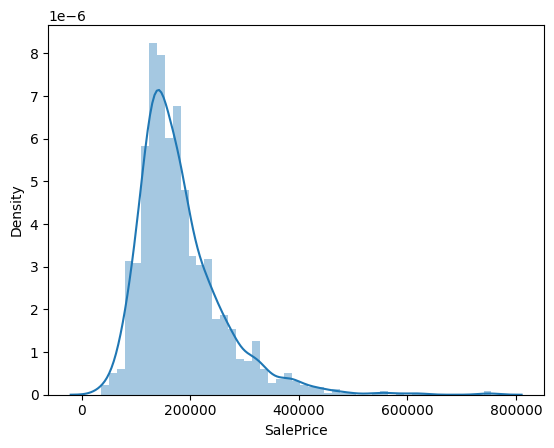

In [7]:
sns.distplot(train_df['SalePrice'])
plt.show()

SalePrice is right-skewed

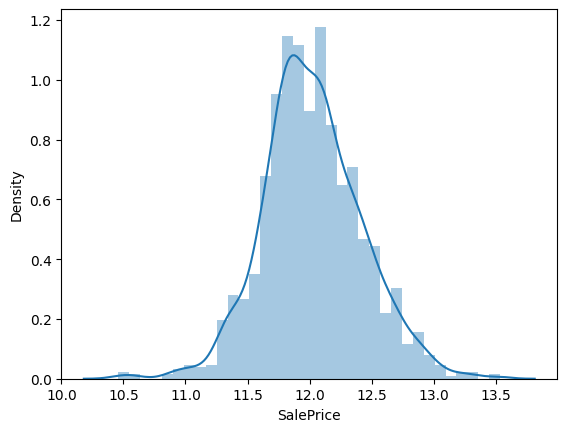

In [8]:
train_df['SalePrice'] = np.log1p(train_df['SalePrice'])
y_train = train_df['SalePrice']
sns.distplot(train_df['SalePrice'])
plt.show()

In [9]:
corr_with_price = train_df.select_dtypes(include=['int64', 'float64']).corr()['SalePrice'].sort_values(ascending=False).head(11)
print(corr_with_price)

SalePrice       1.000000
OverallQual     0.817185
GrLivArea       0.700927
GarageCars      0.680625
GarageArea      0.650888
TotalBsmtSF     0.612134
1stFlrSF        0.596981
FullBath        0.594771
YearBuilt       0.586570
YearRemodAdd    0.565608
GarageYrBlt     0.541073
Name: SalePrice, dtype: float64


# 4. Remove Outliers

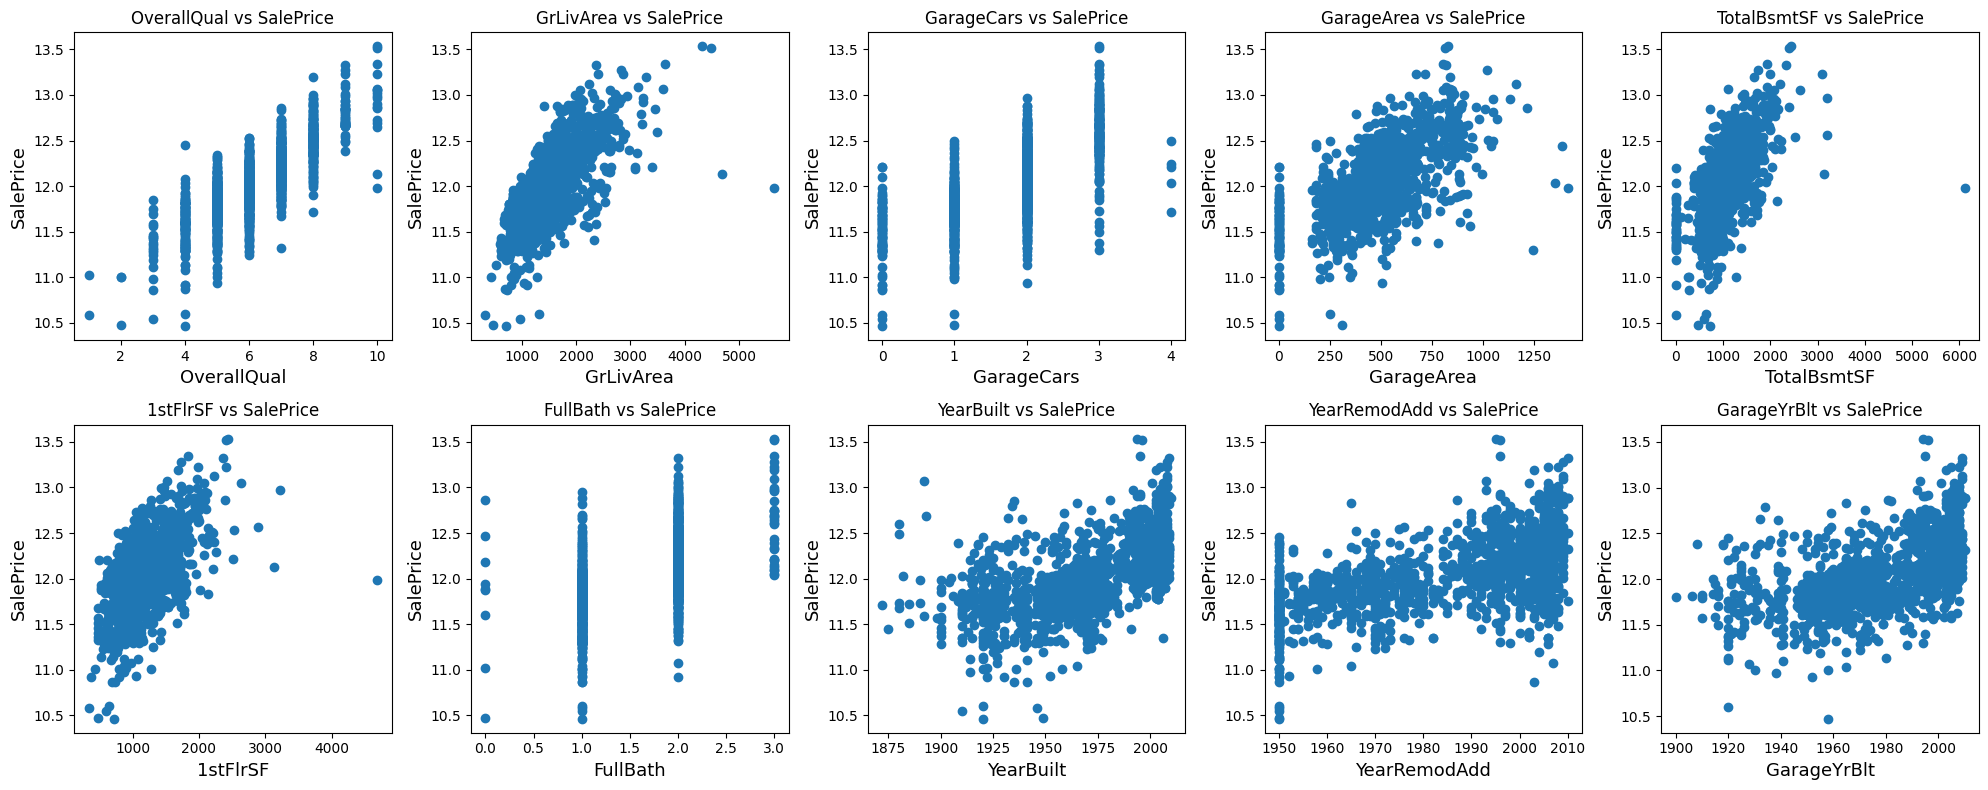

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(corr_with_price.index[1:12]):
    axes[i].scatter(x=train_df[feature], y=train_df['SalePrice'])
    axes[i].set_ylabel('SalePrice', fontsize=13)
    axes[i].set_xlabel(feature, fontsize=13)
    axes[i].set_title(f'{feature} vs SalePrice')

plt.tight_layout()
plt.show()

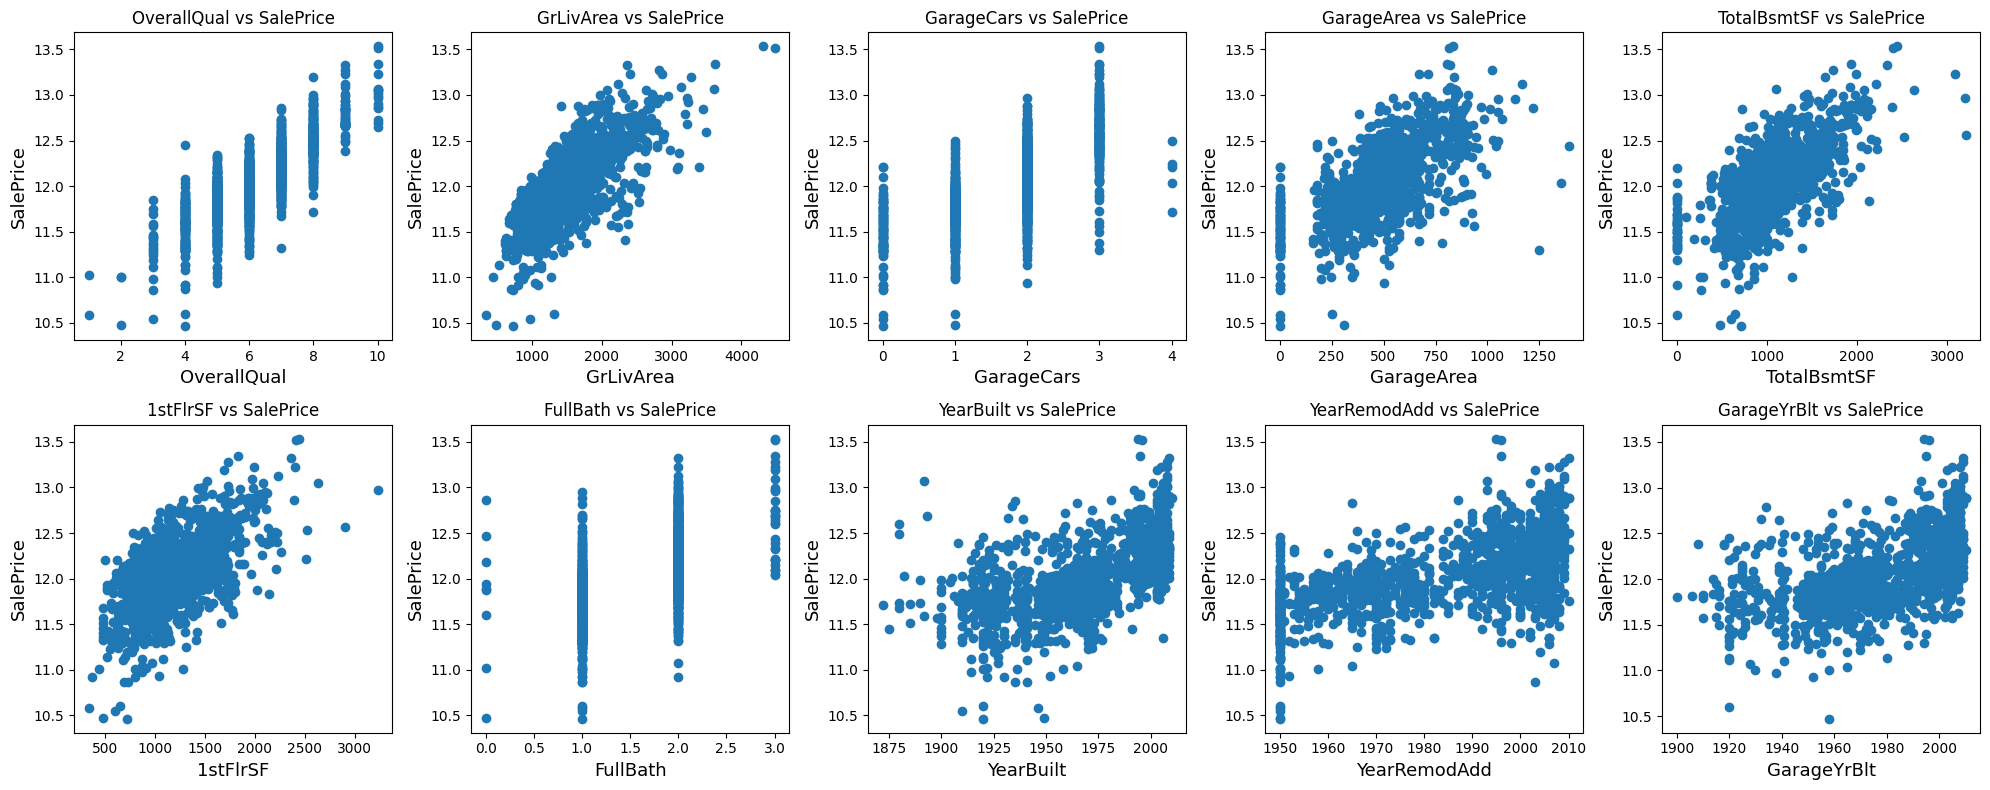

In [11]:
train_df = train_df.drop(train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 12.5)].index)
train_df = train_df.drop(train_df[(train_df['TotalBsmtSF'] > 5000)].index)
train_df = train_df.drop(train_df[(train_df['1stFlrSF'] > 4000)].index)

y_train = train_df['SalePrice']
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(corr_with_price.index[1:12]):
    axes[i].scatter(x=train_df[feature], y=train_df['SalePrice'])
    axes[i].set_ylabel('SalePrice', fontsize=13)
    axes[i].set_xlabel(feature, fontsize=13)
    axes[i].set_title(f'{feature} vs SalePrice')

plt.tight_layout()
plt.show()

# 5. Feature Engineering

Merge train_df and test_df

In [12]:
num_train = train_df.shape[0]
num_test = test_df.shape[0]
all_df = pd.concat((train_df.drop('SalePrice', axis=1), test_df), axis=0).reset_index(drop=True)
print(f"All data shape: {all_df.shape}")

All data shape: (2917, 79)


# 5.1 Missing data imputation

In [13]:
missing = all_df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

PoolQC          2908
MiscFeature     2812
Alley           2719
Fence           2346
MasVnrType      1766
FireplaceQu     1420
LotFrontage      486
GarageFinish     159
GarageQual       159
GarageCond       159
GarageYrBlt      159
GarageType       157
BsmtExposure      82
BsmtCond          82
BsmtQual          81
BsmtFinType2      80
BsmtFinType1      79
MasVnrArea        23
MSZoning           4
BsmtFullBath       2
BsmtHalfBath       2
Functional         2
Utilities          2
GarageArea         1
GarageCars         1
Electrical         1
KitchenQual        1
TotalBsmtSF        1
BsmtUnfSF          1
BsmtFinSF2         1
BsmtFinSF1         1
Exterior2nd        1
Exterior1st        1
SaleType           1
dtype: int64


Drop high missing columns and Utilities because they are useless

In [14]:
drop_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'Utilities']
all_df = all_df.drop(columns=drop_cols, errors="ignore")

Features that na = "None"

In [15]:
for col in ['FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']:
    all_df[col] = all_df[col].fillna('None')

Features that na = 0

In [16]:
for col in ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']:
    all_df[col] = all_df[col].fillna(0)

Use the most common value to replace the missing value

In [17]:
for col in ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType']:
    all_df[col] = all_df[col].fillna(all_df[col].mode()[0])

Use default value - "Typ"

In [18]:
all_df['Functional'] = all_df['Functional'].fillna('Typ')

Use the median LotFrontage of Neighborhood to replace the missing value

In [19]:
all_df['LotFrontage'] = all_df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

Check if there are any missing values

In [20]:
all_df.isna().sum()

MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
LotShape         0
LandContour      0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
KitchenQual      0
TotRmsAbvGrd     0
Functional  

# 5.2 Feature Creation

In [21]:
all_df['TotalSF'] = all_df['TotalBsmtSF'] + all_df['1stFlrSF'] + all_df['2ndFlrSF']
all_df['TotalBath'] = all_df['FullBath'] + 0.5 * all_df['HalfBath'] + all_df['BsmtFullBath'] + 0.5 * all_df['BsmtHalfBath']
all_df['TotalPorchSF'] = all_df['WoodDeckSF'] + all_df['OpenPorchSF'] + all_df['EnclosedPorch'] + all_df['3SsnPorch'] + all_df['ScreenPorch']
all_df['HouseAge'] = all_df['YrSold'] - all_df['YearBuilt']
all_df['RemodAge'] = all_df['YrSold'] - all_df['YearRemodAdd']

In [22]:
all_df['HasPool'] = all_df['PoolArea'].apply(lambda x: 1 if x > 0 else 0)
all_df['Has2ndFlr'] = all_df['2ndFlrSF'].apply(lambda x: 1 if x > 0 else 0)
all_df['HasGarage'] = all_df['GarageArea'].apply(lambda x: 1 if x > 0 else 0)
all_df['HasBsmt'] = all_df['TotalBsmtSF'].apply(lambda x: 1 if x > 0 else 0)
all_df['HasFireplace'] = all_df['Fireplaces'].apply(lambda x: 1 if x > 0 else 0)

# 5.3 Data Transformation

In [23]:
quality_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']
for col in quality_cols:
    all_df[col] = all_df[col].map({'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}).fillna(0)

In [24]:
all_df['BsmtExposure'] = all_df['BsmtExposure'].map({'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0}).fillna(0)
all_df['LotShape'] = all_df['LotShape'].map({'Reg': 3, 'IR1': 2, 'IR2': 1, 'IR3': 0}).fillna(3)
all_df['GarageFinish'] = all_df['GarageFinish'].map({'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0}).fillna(0)

The "MSSubClass" values are presented as numbers, but we believe that using categories would be more appropriate

In [25]:
all_df['MSSubClass'] = all_df['MSSubClass'].astype(str)

Use One-Hot Encoding to process the remaining categorical features

In [26]:
final_df = pd.get_dummies(all_df, drop_first=True)
print(f"Final data shape after dummie: {final_df.shape}")

Final data shape after dummie: (2917, 233)


Separate back to train_df and test_df
Check if the indices of train_df and test_df are aligned because we have removed outliers

In [27]:
x_train = final_df.iloc[:num_train]
x_test = final_df.iloc[num_train:]

x_train = x_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
x_train = x_train.loc[y_train.index]

print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape}")

x_train shape: (1458, 233)
y_train shape: (1458,)
x_test shape: (1459, 233)


# 6. XGBoost

Use Bayesian Optimisation to find out the best parameters of XGBoost

In [28]:
"""
search_spaces = {
    'n_estimators': Integer(1000, 5000),
    'max_depth': Integer(3, 8),
    'learning_rate': Real(0.01, 0.1, prior='log-uniform'),
    'subsample': Real(0.6, 1.0),
    'colsample_bytree': Real(0.6, 1.0),
    'reg_alpha': Real(0, 1),
    'reg_lambda': Real(0, 1)
}

xgb = XGBRegressor(random_state=42, n_jobs=-1)

bayes_search = BayesSearchCV(
    estimator=xgb,
    search_spaces=search_spaces,
    n_iter=30,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

bayes_search.fit(x_train, y_train)

print("Best parameters:", bayes_search.best_params_)
print("Best CV score:", np.sqrt(-bayes_search.best_score_))
"""

'\nsearch_spaces = {\n    \'n_estimators\': Integer(1000, 5000),\n    \'max_depth\': Integer(3, 8),\n    \'learning_rate\': Real(0.01, 0.1, prior=\'log-uniform\'),\n    \'subsample\': Real(0.6, 1.0),\n    \'colsample_bytree\': Real(0.6, 1.0),\n    \'reg_alpha\': Real(0, 1),\n    \'reg_lambda\': Real(0, 1)\n}\n\nxgb = XGBRegressor(random_state=42, n_jobs=-1)\n\nbayes_search = BayesSearchCV(\n    estimator=xgb,\n    search_spaces=search_spaces,\n    n_iter=30,\n    scoring=\'neg_mean_squared_error\',\n    cv=5,\n    n_jobs=-1,\n    random_state=42,\n    verbose=1\n)\n\nbayes_search.fit(x_train, y_train)\n\nprint("Best parameters:", bayes_search.best_params_)\nprint("Best CV score:", np.sqrt(-bayes_search.best_score_))\n'

Best parameters: OrderedDict([('colsample_bytree', 0.6), ('learning_rate', 0.01), ('max_depth', 3), ('n_estimators', 5000), ('reg_alpha', 0.0), ('reg_lambda', 1.0), ('subsample', 0.6)])

Best CV score: 0.11465269257054235

In [29]:
xgb_model = XGBRegressor(n_estimators=5000, max_depth=3, learning_rate=0.01, subsample=0.6, colsample_bytree=0.6, reg_alpha=0.0, reg_lambda=1.0, random_state=42, n_jobs=-1)
xgb_model.fit(x_train, y_train)
xgb_scores = cross_val_score(xgb_model, x_train, y_train, cv=5, scoring='neg_mean_squared_error')
xgb_rmse = np.sqrt(-xgb_scores.mean())
print(f"XGBoost CV RMSE: {xgb_rmse:,.6f}")

XGBoost CV RMSE: 0.114653


In [30]:
xgb_predictions = np.expm1(xgb_model.predict(x_test))

# 7. Create Submission

In [31]:
submission = pd.DataFrame({
    'Id': test_id,
    'SalePrice': xgb_predictions
})

submission.to_csv("submission.csv", index=False)

submission.head()

,Id,SalePrice
0,1461,124409.078125
1,1462,158931.125000
2,1463,186248.406250
3,1464,198130.984375
4,1465,186217.500000
